# 02 · Parser and PC algorithm
**Owner:** Rakshita

Turn every premise and hypothesis into structured facts, then run the PC algorithm to find the causal graph of
each premise. These are fixed rules that never learn from labels, so running them on all splits is not leakage.

In [1]:
# ─── IMPORTS ─────
import re
import itertools
import warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.base import DAG
from pgmpy.causal_discovery import PC
from pgmpy.independencies import Independencies

warnings.filterwarnings("ignore")

In [2]:
# ─── LOAD DATA ─────
train = pd.read_csv("../data/processed/train.csv")
validation = pd.read_csv("../data/processed/validation.csv")
test = pd.read_csv("../data/processed/test.csv")

data = pd.concat([train, validation, test], ignore_index=True)
data.head()

,premise_id,split,premise,hypothesis,label,num_variables,template
0,18,train,Suppose there is a closed system of 5 variable...,E directly causes B.,0,5,child
1,25,train,Suppose there is a closed system of 5 variable...,"E is a cause for D, but not a direct one.",0,5,non-child descendant
2,25,train,Suppose there is a closed system of 5 variable...,E directly causes D.,0,5,child
3,25,train,Suppose there is a closed system of 5 variable...,D causes something else which causes E.,0,5,non-parent ancestor
4,25,train,Suppose there is a closed system of 5 variable...,D directly causes E.,0,5,parent


In [3]:
# ─── STEP 1: PARSE THE HYPOTHESES ─────
def parse_hypothesis(df):
    # the two variables are the single capital letters in the sentence
    letters = df["hypothesis"].str.findall(r"\b[A-Z]\b")
    df["x"] = letters.str[0]
    df["y"] = letters.str[1]

    # the claim type comes from the wording
    df["relation"] = "unknown"
    df.loc[df["hypothesis"].str.contains("directly causes"), "relation"] = "direct_cause"
    df.loc[df["hypothesis"].str.contains("something else which causes|but not a direct one"), "relation"] = "indirect_cause"
    df.loc[df["hypothesis"].str.contains("collider"), "relation"] = "collider"
    df.loc[df["hypothesis"].str.contains("confounder"), "relation"] = "confounder"
    return df


data = parse_hypothesis(data)

# the variables listed in the premise, e.g. "A, B, C"
data["variables"] = data["premise"].str.extract(r"variables, (.*?)\. All")[0].str.replace(" and ", ", ")

data[["hypothesis", "relation", "x", "y", "variables"]].head()

,hypothesis,relation,x,y,variables
0,E directly causes B.,direct_cause,E,B,"A, B, C, D, E"
1,"E is a cause for D, but not a direct one.",indirect_cause,E,D,"A, B, C, D, E"
2,E directly causes D.,direct_cause,E,D,"A, B, C, D, E"
3,D causes something else which causes E.,indirect_cause,D,E,"A, B, C, D, E"
4,D directly causes E.,direct_cause,D,E,"A, B, C, D, E"


In [4]:
# each dataset template should map to one relation
pd.crosstab(data["template"], data["relation"])

relation,collider,confounder,direct_cause,indirect_cause
template,,,,
child,0,0,6253,0
has_collider,6259,0,0,0
has_confounder,0,6259,0,0
non-child descendant,0,0,0,6291
non-parent ancestor,0,0,0,6214
parent,0,0,6252,0


"parent" and "child" both become `direct_cause` because their text is the same.

In [5]:
# ─── STEP 2: SCHEMA RULES ─────
# only A-F are allowed, no self-loops (A -> A), and both variables must be in the premise
def check_schema(df):
    checks = pd.DataFrame()
    checks["outside A-F"] = ~df["x"].isin(list("ABCDEF")) | ~df["y"].isin(list("ABCDEF"))
    checks["self-loop"] = df["x"] == df["y"]
    checks["not in premise"] = ~df.apply(lambda row: str(row["x"]) in row["variables"] and str(row["y"]) in row["variables"], axis=1)
    checks["unknown wording"] = df["relation"] == "unknown"
    return checks


# number of rows that break each rule
check_schema(data).sum()

outside A-F        0
self-loop          0
not in premise     0
unknown wording    0
dtype: int64

In [6]:
# some broken hypotheses, to show the rules catch them
broken = pd.DataFrame({
    "hypothesis": ["C directly causes C.", "A directly causes G.", "A directly causes F.", "A and B are friends."],
    "variables": ["A, B, C", "A, B, C", "A, B, C", "A, B, C"],
})
broken = parse_hypothesis(broken)
pd.concat([broken["hypothesis"], check_schema(broken)], axis=1)

,hypothesis,outside A-F,self-loop,not in premise,unknown wording
0,C directly causes C.,False,True,False,False
1,A directly causes G.,True,False,True,False
2,A directly causes F.,False,False,True,False
3,A and B are friends.,False,False,False,True


In [7]:
# ─── STEP 3: PC ALGORITHM ─────
# PC normally tests independence on numbers. Here the premise already states the independences, so we give
# them to pgmpy directly (ci_test="independence_match"). pgmpy still needs a table with the variable names,
# so we pass two rows of zeros that are never used.
def find_graph(premise):
    variables = re.search(r"variables, (.*?)\. All", premise).group(1).replace(" and ", ", ").split(", ")

    independencies = Independencies()
    for x, y in re.findall(r"([A-F]) is independent of ([A-F])\.", premise):
        independencies.add_assertions([x, y])
    for x, y, given in re.findall(r"([A-F]) and ([A-F]) are independent given (.*?)\.", premise):
        independencies.add_assertions([x, y, given.replace(" and ", ", ").split(", ")])

    pc = PC(variant="orig", ci_test="independence_match", show_progress=False)
    pc.fit(pd.DataFrame(0, index=[0, 1], columns=variables), independencies=independencies)
    return pc.causal_graph_


# one graph per premise
graphs = data.drop_duplicates("premise_id")[["premise_id", "split", "premise", "variables"]].copy()
graphs["pdag"] = graphs["premise"].apply(find_graph)
graphs.shape

(440, 5)

In [8]:
# one example
example = graphs[graphs["premise"].str.contains("closed system of 3 variables")].iloc[0]
print(example["premise"])
print("directed:  ", example["pdag"].directed_edges)
print("undirected:", example["pdag"].undirected_edges)

Suppose there is a closed system of 3 variables, A, B and C. All the statistical relations among these 3 variables are as follows: A correlates with B. However, A is independent of C. A and C are independent given B. B is independent of C. B and C are independent given A.
directed:   set()
undirected: {('A', 'B')}


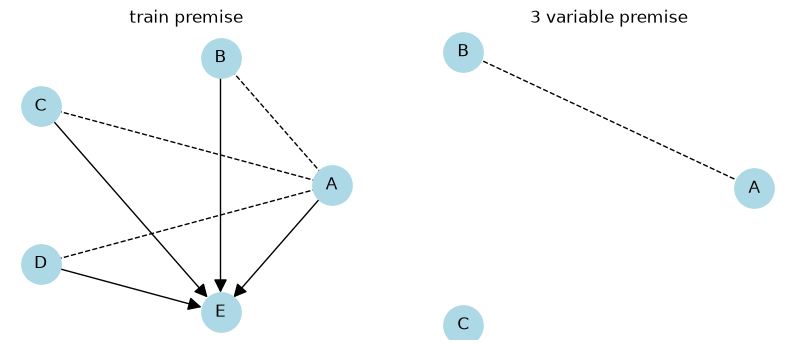

In [9]:
# draw a graph: arrows = direction is known, dashed = direction can't be known
def draw(pdag, ax, title):
    pos = nx.circular_layout(sorted(pdag.nodes))
    nx.draw_networkx_nodes(pdag, pos, ax=ax, node_color="lightblue", node_size=800)
    nx.draw_networkx_labels(pdag, pos, ax=ax)
    nx.draw_networkx_edges(nx.DiGraph(list(pdag.directed_edges)), pos, ax=ax, arrowsize=20, node_size=800)
    nx.draw_networkx_edges(nx.Graph(list(pdag.undirected_edges)), pos, ax=ax, style="dashed")
    ax.set_title(title)
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
draw(graphs["pdag"].iloc[0], axes[0], "train premise")
draw(example["pdag"], axes[1], "3 variable premise")
plt.show()

In [10]:
# ─── STEP 4: ALL GRAPHS THAT FIT THE PREMISE ─────
# PC can leave some edges undirected. We try both directions for every undirected edge and keep the
# ones that are a DAG and I-equivalent (same skeleton and colliders) to the PC graph.
def all_dags(pdag):
    one_dag = pdag.to_dag()
    undirected = list(pdag.undirected_edges)
    dags = []
    for flips in itertools.product([False, True], repeat=len(undirected)):
        dag = DAG()
        dag.add_nodes_from(pdag.nodes)
        dag.add_edges_from(pdag.directed_edges)
        dag.add_edges_from([(b, a) if flip else (a, b) for (a, b), flip in zip(undirected, flips)])
        if nx.is_directed_acyclic_graph(dag) and dag.is_iequivalent(one_dag):
            dags.append(dag)
    return dags


graphs["dags"] = graphs["pdag"].apply(all_dags)
graphs["mec_size"] = graphs["dags"].str.len()
graphs["mec_size"].value_counts()

mec_size
1      122
2       88
3       64
4       60
8       26
6       26
10      15
5       10
13       7
14       5
12       4
20       3
18       3
24       2
88       1
144      1
17       1
42       1
32       1
Name: count, dtype: int64

In [11]:
# ─── STEP 5: IS THE CLAIM TRUE IN THOSE GRAPHS? ─────
def claim_is_true(dag, relation, x, y):
    if relation == "direct_cause":
        return dag.has_edge(x, y)
    if relation == "indirect_cause":
        return not dag.has_edge(x, y) and y in nx.descendants(dag, x)
    if relation == "collider":
        return len(set(dag.successors(x)) & set(dag.successors(y))) > 0
    if relation == "confounder":
        return len(set(dag.predecessors(x)) & set(dag.predecessors(y))) > 0


# mec_support = share of possible graphs where the claim is true (1 means it must be true)
dags_of = graphs.set_index("premise_id")["dags"]


def mec_support(row):
    dags = dags_of[row["premise_id"]]
    return np.mean([claim_is_true(dag, row["relation"], row["x"], row["y"]) for dag in dags])


data["mec_support"] = data.apply(mec_support, axis=1)
data[["hypothesis", "label", "mec_support"]].head()

,hypothesis,label,mec_support
0,E directly causes B.,0,0.0
1,"E is a cause for D, but not a direct one.",0,0.0
2,E directly causes D.,0,0.0
3,D causes something else which causes E.,0,0.5
4,D directly causes E.,0,0.0


In [12]:
# ─── STEP 6: DO THE GRAPHS EXPLAIN THE LABELS? ─────
# a claim is valid if it is true in every possible graph
data["pc_label"] = (data["mec_support"] == 1).astype(int)
data["agrees"] = data["pc_label"] == data["label"]
data.groupby("split")["agrees"].mean()

split
test          0.962134
train         0.936786
validation    0.964912
Name: agrees, dtype: float64

In [13]:
data.pivot_table(index="template", columns="split", values="agrees").round(3)

split,test,train,validation
template,,,
child,1.000,1.000,1.000
has_collider,0.933,0.888,0.903
has_confounder,0.979,0.960,0.989
non-child descendant,0.964,0.932,0.994
non-parent ancestor,0.938,0.925,0.976
parent,0.959,0.917,0.929


The parser + PC reproduce about 94–96% of the labels, so the parsing is correct. The rest are cases where the
dataset's label differs from what PC concludes, which we treat as a limitation of the dataset.

In [14]:
# ─── STEP 7: SAVE AS CSV ─────
graphs["directed_edges"] = graphs["pdag"].apply(lambda g: ";".join(sorted(f"{a}->{b}" for a, b in g.directed_edges)))
graphs["undirected_edges"] = graphs["pdag"].apply(lambda g: ";".join(sorted("-".join(sorted(e)) for e in g.undirected_edges)))

graphs[["premise_id", "split", "variables", "directed_edges", "undirected_edges", "mec_size"]].to_csv(
    "../data/processed/premise_graphs.csv", index=False)
data.drop(columns=["pc_label", "agrees"]).to_csv("../data/processed/parsed.csv", index=False)